# Chapter 1. The trend sleeve, and what it costs to run

**Question.** Can a simple time-series momentum sleeve, stacked on top of a
100% equity position, improve the equity investor's book?

**Covers:**
1. the signal and the two tiers of volatility targeting;
2. the first universe: seven Bloomberg futures, one or two per asset class;
3. the sleeve alone, sub-periods, and stacked on the S&P;
4. management-fee drag and per-trade transaction costs;
5. weekly against monthly rebalancing.

**Every number here is produced by today's engine.** Earlier versions of these results ran on an engine with a start-up leverage defect (see `docs/BUGFIX_LOG.md`,
E4) that inflated full-sample figures; where the original number differs it
is quoted in the text.

**Configuration, unless a cell says otherwise:** the lean 7 markets, weekly
rebalancing, 12% portfolio volatility target, gross of costs, Sharpe after
the US risk-free rate, out of sample from 2008-09-04.

In [1]:
from _setup import *
from ctadata import LEAN_7, symbols_of
from cta.config import apply_fee_drag, FEE_BPS, TRANSACTION_COST_BPS

LEAN = symbols_of(LEAN_7)
print("lean 7:", LEAN_7)
print(f"data {df.index.min().date()} to {df.index.max().date()}, {len(df)} rows")

lean 7: {'fixed_income': ['us10y', 'eurobund'], 'equities': ['spx'], 'commodities': ['gold', 'wti'], 'currencies': ['eur', 'aud']}
data 2006-09-04 to 2026-09-28, 5189 rows


## 1. The strategy in four lines

For each market, every day, using only information up to yesterday:

```
score   = 0.5 * sign(40-day return) + 0.5 * sign(252-day return)     in {-1, 0, +1}
weight  = score * 20% / own trailing 60-day volatility                 Tier 1, capped at 3x
lev     = 12% / trailing 60-day volatility of the unlevered book        Tier 2, capped at 4x
held    = weight * lev, reset on the first trading day of each period
```

* **Time-series, not cross-sectional.** Each market is judged only against
  its own past, so the book can be net short a whole asset class. A
  cross-sectional ranking is always long something, and crisis returns come
  precisely from being able to go short everything.
* **Barbell horizons.** A fast and a slow leg, no middle. Disagreement means
  flat: the market is at a turning point and the signal abstains.
* **Two tiers of volatility targeting.** Tier 1 stops any one market
  dominating on size; Tier 2 holds the whole book at a constant risk. The
  literature finds the volatility scaling carries most of momentum's
  apparent predictability, so it is treated as the core, not a refinement.

In [2]:
nav, lev, w = build_trend_nav(df, symbols=LEAN, **DEFAULT_PARAMS)
r_lean = returns(nav)
print(f"first trading day: {lev[lev > 0].index[0].date()}  (the 252-day warm-up)")
print(f"median leverage multiplier when live: {lev[lev > 0].median():.2f}")
describe({"lean 7, weekly, gross": r_lean}, stacked=True)

first trading day: 2007-11-26  (the 252-day warm-up)
median leverage multiplier when live: 0.26


,sharpe,vol,cagr,max_dd,stacked_sharpe,stacked_cagr,stacked_max_dd
"lean 7, weekly, gross",0.1918,0.1366,0.0323,-0.2901,0.6354,0.1473,-0.3770


The leverage multiplier is the Tier-2 scalar, not the book's notional. The
notional is `sum(|weight| * lev)` and runs far higher, which matters for
financing (Chapter 9).

In [3]:
side = np.sign(w[LEAN]).replace({1.0: "long", -1.0: "short", 0.0: "flat"})
(side.apply(lambda c: c.value_counts(normalize=True)).T * 100).round(1)

,flat,long,short
us10y,45.3000,29.1000,25.6000
eurobund,40.6000,33.6000,25.8000
spx,36.5000,52.9000,10.6000
gold,43.5000,39.3000,17.2000
wti,44.5000,31.5000,24.0000
eur,46.7000,25.9000,27.3000
aud,46.7000,24.6000,28.7000


## 2. Is the full-sample number real? Sub-periods

A full-sample Sharpe can be one lucky window. Five-year chunks show how
uneven this book is: almost all of its return arrives in 2016-2020, and
2011-2015 is the "trend drought" the managed-futures industry also lived
through.

An earlier version of this analysis showed a Sharpe of 0.76 for 2006-2010 (0% rate). Most of that
was the start-up leverage defect: the book opened at the 4x cap in late
2007, just before the 2008 trends. On the corrected engine the same window
is flat. This is the clearest single illustration of why that bug mattered.

In [4]:
def by_period(r, years=5):
    out = {}
    for start in range(2006, 2027, years):
        s = r[(r.index.year >= start) & (r.index.year < start + years)]
        if len(s) > 60:
            out[f"{start}-{min(start + years - 1, 2026)}"] = dict(
                sharpe=sharpe(s, RF), total_return=(1 + s).prod() - 1)
    return pd.DataFrame(out).T

by_period(r_lean)

,sharpe,total_return
2006-2010,-0.1194,-0.0011
2011-2015,0.0091,-0.0322
2016-2020,0.5901,0.5381
2021-2025,0.0484,0.1597
2026-2026,0.2402,0.0461


## 3. Stacked on the S&P

The point of the sleeve is not to beat the S&P on its own. It is to be
added to an existing S&P position on the same capital: futures need only a
few percent of notional as margin, so the capital that holds the index can
also carry the trend book. The stacked return is simply
`S&P return + sleeve return`.

In [5]:
stack = {"S&P alone": SPX, "sleeve alone": r_lean, "S&P + sleeve": SPX + r_lean}
print("correlation, sleeve vs S&P (out of sample):",
      round(oos(r_lean).corr(oos(SPX)), 3))
describe(stack)

correlation, sleeve vs S&P (out of sample): -0.064


,sharpe,vol,cagr,max_dd
S&P alone,0.5455,0.1947,0.1096,-0.4251
sleeve alone,0.1918,0.1366,0.0323,-0.2901
S&P + sleeve,0.6354,0.2306,0.1473,-0.3770


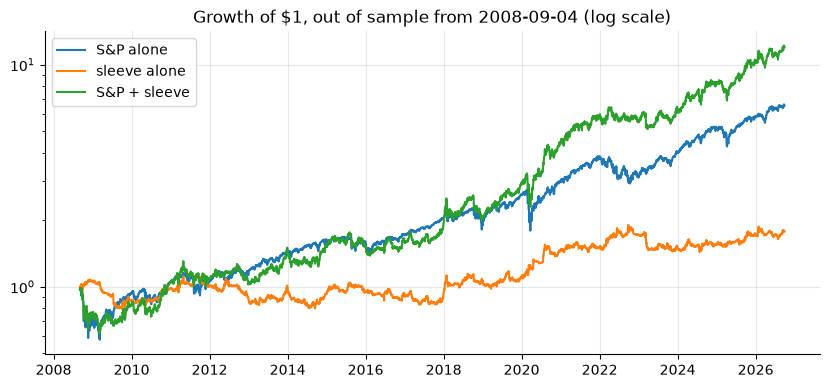

In [6]:
fig, ax = plt.subplots()
for k, v in stack.items():
    ax.plot((1 + oos(v)).cumprod(), label=k)
ax.set_yscale("log"); ax.set_title("Growth of $1, out of sample from 2008-09-04 (log scale)")
ax.legend(); plt.show()

## 4. Fees

A first, gentle cost model: an annual expense ratio spread evenly over the
year, from comparable products (0.35%, 0.75%, 0.99%). Charged to the sleeve
only; the equity leg is a near-costless index position.

In [7]:
fees = {"gross": r_lean}
for k in ("low", "base", "high"):
    fees[f"net of {FEE_BPS[k]} bp fee"] = apply_fee_drag(r_lean, k)
describe(fees, stacked=True)

,sharpe,vol,cagr,max_dd,stacked_sharpe,stacked_cagr,stacked_max_dd
gross,0.1918,0.1366,0.0323,-0.2901,0.6354,0.1473,-0.3770
net of 35 bp fee,0.1662,0.1366,0.0286,-0.2978,0.6202,0.1432,-0.3781
net of 75 bp fee,0.1369,0.1366,0.0244,-0.3064,0.6029,0.1385,-0.3794
net of 99 bp fee,0.1193,0.1366,0.0219,-0.3116,0.5925,0.1357,-0.3802


## 5. Transaction costs

The realistic cost is per trade. `TRANSACTION_COST_BPS` holds a one-way
cost per unit of notional traded (half-spread, commission, slippage),
tiered by liquidity: 2 bp for the most liquid futures up to 4.5 bp for thin
ones, from CTA replication research that calls a volume-weighted 2 bp round
turn realistic. The engine charges it on turnover in **leverage-scaled**
weight at every rebalance, because that is what is actually traded.

There is deliberately no financing charge: a future's cost of carry is
already in its price, so charging it again would double-count.

In [8]:
pd.Series({s: TRANSACTION_COST_BPS[s] * 1e4 for s in LEAN}, name="bp one way").to_frame().T

,us10y,eurobund,spx,gold,wti,eur,aud
bp one way,2.0000,2.5000,2.0000,3.5000,4.0000,2.0000,3.5000


In [9]:
costed = {"gross": r_lean}
for m in (1, 2, 3, 5):
    costed[f"net, {m}x cost table"] = returns(build_trend_nav(
        df, symbols=LEAN, apply_costs=True, cost_multiplier=m, **DEFAULT_PARAMS)[0])
describe(costed, stacked=True)

,sharpe,vol,cagr,max_dd,stacked_sharpe,stacked_cagr,stacked_max_dd
gross,0.1918,0.1366,0.0323,-0.2901,0.6354,0.1473,-0.3770
"net, 1x cost table",0.0834,0.1367,0.0167,-0.3377,0.5711,0.1300,-0.3783
"net, 2x cost table",-0.0249,0.1368,0.0014,-0.4139,0.5068,0.1130,-0.3796
"net, 3x cost table",-0.1330,0.1369,-0.0137,-0.4897,0.4424,0.0962,-0.3809
"net, 5x cost table",-0.3483,0.1373,-0.0433,-0.6132,0.3137,0.0633,-0.3834


For this lean seven-market book, costs nearly erase the standalone edge:
net of the cost table and after the risk-free rate the sleeve is barely
positive, and at twice the costs it is negative. The stacked book stays
well above the S&P alone at every cost level, because the sleeve's value is
diversification rather than standalone return. (Earlier run on the old engine, full sample, 0% rate: 0.43 gross to 0.32 net.)

A standalone edge this thin is what pushed the project toward more markets
(Chapter 4).

## 6. Weekly or monthly?

Monthly rebalancing trades about half as much, so its cost drag is less
than half of weekly's and its net Sharpe is higher. But on this seven-market
universe it carries a far deeper drawdown, a three-year slide from
September 2011 to October 2014, so weekly was kept at this stage. The question was reopened on the
final universe with a proper walk-forward, and there monthly won: the same
signal for less cost in 7 of 7 windows (Chapter 5).

In [10]:
freq = {}
for f, label in (("W", "weekly"), ("M", "monthly")):
    kw = {**DEFAULT_PARAMS, "rebalance_freq": f}
    freq[f"{label}, gross"] = returns(build_trend_nav(df, symbols=LEAN, **kw)[0])
    freq[f"{label}, net"] = returns(build_trend_nav(df, symbols=LEAN, apply_costs=True, **kw)[0])
t = describe(freq)
t["cost_drag_pts_pa"] = np.nan
for label in ("weekly", "monthly"):
    t.loc[f"{label}, net", "cost_drag_pts_pa"] = 100 * (t.loc[f"{label}, gross", "cagr"]
                                                       - t.loc[f"{label}, net", "cagr"])
t

,sharpe,vol,cagr,max_dd,cost_drag_pts_pa
"weekly, gross",0.1918,0.1366,0.0323,-0.2901,NaN
"weekly, net",0.0834,0.1367,0.0167,-0.3377,1.5571
"monthly, gross",0.2193,0.1450,0.0370,-0.4710,NaN
"monthly, net",0.1739,0.1450,0.0300,-0.4846,0.6994


## What this chapter established

* A simple barbell TSMOM sleeve on seven markets has a thin standalone
  edge, concentrated in a few years, and a slightly negative correlation to
  the S&P.
* Its value is as a **stack**: added to an equity position it raises the
  return of the combined book without a matching rise in drawdown.
* Transaction costs matter a great deal at this breadth. Every later
  chapter reports results **net** of the cost table and after the
  risk-free rate.
* Everything here is still full-sample. Chapter 3 asks whether any of it
  survives being tested on data the choices never saw.